# Tools - removing cycles

This notebook illustrates how to simplify a graph by removing simple cycles, using the function `kn.tools.remove_simple_cycles`.

The nodes of any cycle whose length (in number of nodes) not exceeding `max_cylcle_len` (if specified) are removed and replaced by one node, and the edges issued from the removed nodes are removed and replaced by new edges issued from the new node.

The procedure is iterative: at each iteration, only cycles that don't share common nodes are treated. Finally:
- the set of output nodes (labels) is a subset of the set of input nodes (labels)
- the node attributes in the output graph are computed according to the attributes of the nodes merged (aggregated) from the input graph, according to the parameter `node_attr_mode`
- the edge attributes are not considered for new edges

The function returns an output graph (simplified as described above) and, optionally, the dictionary of merged nodes from the input graph, and / or the dictionary of the number of merged nodes from the input graph (see example below).

*Note: this function should not be used if too many cycles are present (the function `networkx.simple_cycles`, used to identify the cycles, can be very time consuming in this case).*



In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import scipy
# import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.7


## Define an input graph

In [5]:
# The dictionary of nodes of the graph
# - "key : value" corresponds to "node label: node position"
# Note:  the node label may be an integer or a string
nodes = {
     1 : ( 0  , 0  ), 
     2 : ( 0  , 1  ), 
     3 : (-1  , 2  ), 
     4 : ( 1  , 2  ),
    'a': (-1.5, 3  ), 
     6 : (-0.5, 3  ), 
     7 : ( 0.5, 3  ), 
     8 : ( 1.5, 3  ),
     9 : (-2  , 4  ), 
    10 : (-1  , 4  ), 
    11 : ( 0  , 4  ), 
    12 : ( 1  , 4  ), 
    'x': ( 0.5, 5  ),
    14 : (-0.5, 1.1), 
    15 : ( 0.7, 0.5),
    16 : ( 2  , 1.1), 
    17 : ( 2.4, 1.5),
    18 : ( 2.9, 1.2),
    19 : ( 2.5, 0.8)
}

# The list of edges connecting the nodes
# Note: and edge is an unordered pair, i.e. 
#   "(label1, label2)" and "(label2, label1)" describe the same edge)
edges = [
    (   1,   2 ), 
    (   2,  15 ), 
    (  15,   4 ), 
    (   3, 'a' ), 
    (   3,   6 ), 
    (   4,   7 ),
    (   6,   7 ), 
    (   6,  11 ),
    (   4,   8 ), 
    ( 'a',   9 ), 
    ( 'a',  10 ), 
    (   7,  11 ), 
    (   7,  12 ), 
    (   7, 'x' ),
    (   2,  14 ),
    (  14,   3 ),
    (   9,  10 ), 
    (  16,  17 ),
    (  17,  18 ),
    (  18,  19 ),
    (  19,  16 )
]

# Creation of an instance kg of the KGraph object using karstnet
kg = kn.KGraph(edges, nodes)

# Extract the underlying networkx graph
g = kg.graph



This network contains 2 connected components
   This network contains 2 looping branch.es. 
   Tortuosity is infinite on a looping branch. 
   The looping branches are not considered for the mean tortuosity computation.



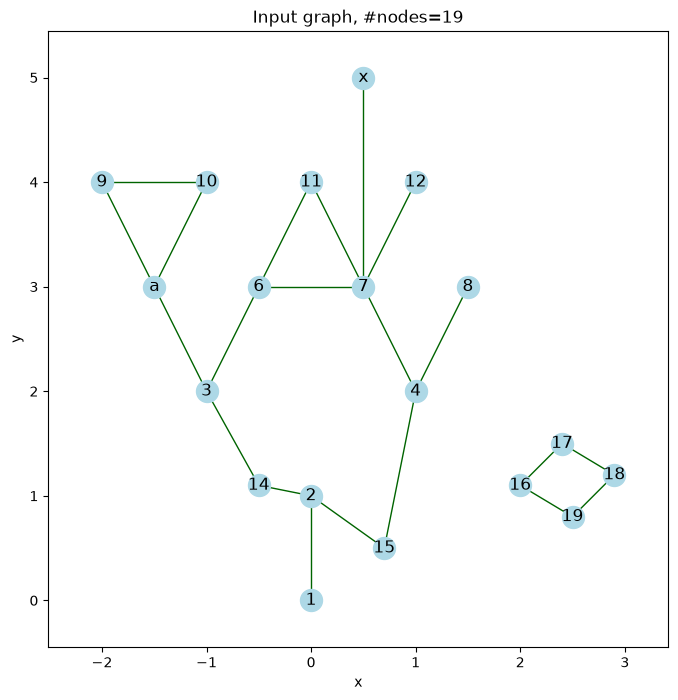

In [6]:
# Options for plot of 2D graph
options = {
    'node_size'   : 250,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'darkgreen', # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the input graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'Input graph, #nodes={g.number_of_nodes()}')
plt.show()

## Removing cycles

### Removing cycles of any length

In [7]:
g_out, node_merging_count_dict, node_merging_list_dict = kn.tools.remove_simple_cycles(
            g, 
            n_iter_max=None, 
            max_cycle_len=None, 
            node_attr_list=None,   # default: try to keep all node attributes 
            node_attr_mode='mean', # default
            return_node_merging_count_dict=True,
            return_node_merging_list_dict=True,
            verbose=1)

Iteration 1 : number of cycles to simplify = 3
Iteration 2 : number of cycles to simplify = 0


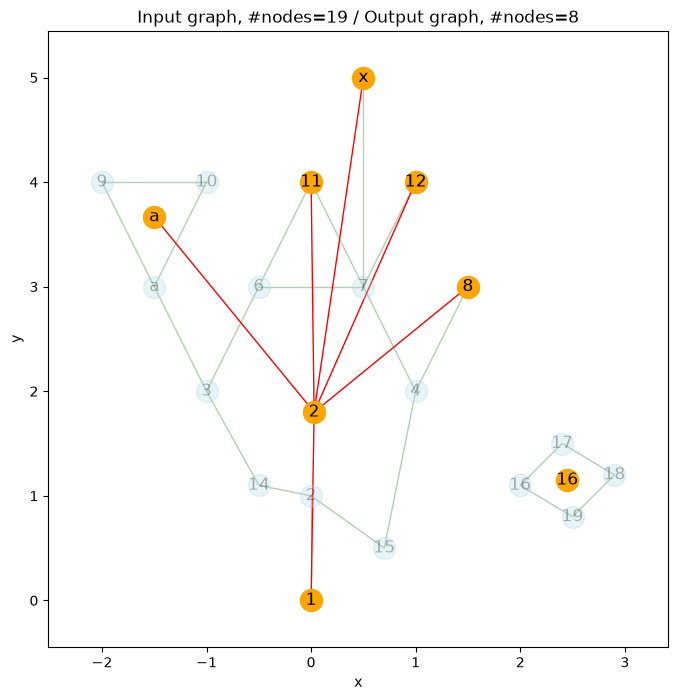

In [8]:
# Options for plot of 2D graph
options_out = {
    'node_size'   : 250,      # node size
    'node_color'  : 'orange', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,        # edge width
    'edge_color'  : 'red',    # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,     # show node labels ?
    #
    # axes
    'show_ticks'  : True,     # show ticks ?
    'axis_equal'  : True      # aspect ratio equal ?
}

# Plot
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options, alpha=0.3)
kn.view.plot_graph2d(g_out, **options_out)
plt.title(f'Input graph, #nodes={g.number_of_nodes()} / Output graph, #nodes={g_out.number_of_nodes()}')
plt.show()

In [9]:
# Get information from `node_merging_count_dict`
nodes_removed = [n for n, c in node_merging_count_dict.items() if c == 0]
nodes_same    = [n for n, c in node_merging_count_dict.items() if c == 1]
nodes_new     = [n for n, c in node_merging_count_dict.items() if c > 1]
print('Removed nodes from input graph:', nodes_removed)
print('Same nodes as in input graph  :', nodes_same)
print('New nodes (aggregating several nodes in input graph):', nodes_new)
for n in nodes_new:
    print(f'- in ouput graph: new node {n} represents {node_merging_count_dict[n]} nodes from the input graph')

Removed nodes from input graph: [3, 4, 6, 7, 9, 10, 14, 15, 17, 18, 19]
Same nodes as in input graph  : [1, 8, 11, 12, 'x']
New nodes (aggregating several nodes in input graph): [2, 'a', 16]
- in ouput graph: new node 2 represents 7 nodes from the input graph
- in ouput graph: new node a represents 3 nodes from the input graph
- in ouput graph: new node 16 represents 4 nodes from the input graph


In [10]:
# Get information from `node_merging_list_dict`
print('In ouput graph:')
for u, u_list in node_merging_list_dict.items():
    if len(u_list) == 0:
        print(f'- node {u} has been removed')    
   
    elif len(u_list) == 1:
        print(f'- node {u} is unchanged (same as in input graph)')    

    else:
        print(f'- node {u} is a merging (aggregation) of the input graph nodes: {u_list}')


In ouput graph:
- node 1 is unchanged (same as in input graph)
- node 2 is a merging (aggregation) of the input graph nodes: [2, 15, 4, 7, 6, 3, 14]
- node 3 has been removed
- node 4 has been removed
- node a is a merging (aggregation) of the input graph nodes: ['a', 9, 10]
- node 6 has been removed
- node 7 has been removed
- node 8 is unchanged (same as in input graph)
- node 9 has been removed
- node 10 has been removed
- node 11 is unchanged (same as in input graph)
- node 12 is unchanged (same as in input graph)
- node x is unchanged (same as in input graph)
- node 14 has been removed
- node 15 has been removed
- node 16 is a merging (aggregation) of the input graph nodes: [16, 17, 18, 19]
- node 17 has been removed
- node 18 has been removed
- node 19 has been removed


In [11]:
np.all([node_merging_count_dict[u] == len(node_merging_list_dict[u]) for u in g.nodes]) # Should be True

np.True_

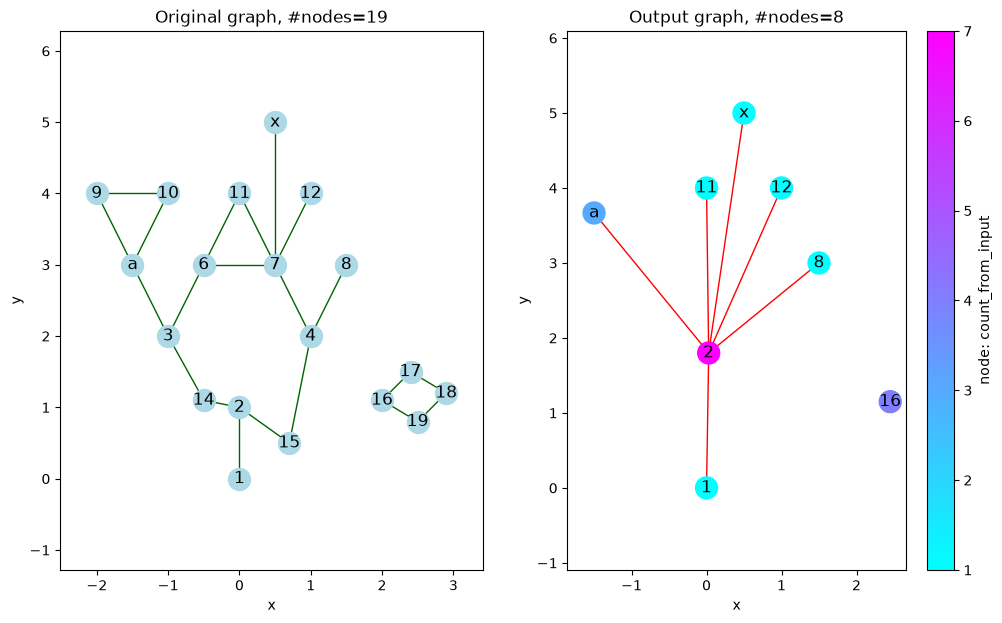

In [12]:
# Plot output graph nodes according to `node_merging_count_dict`
nx.set_node_attributes(g_out, node_merging_count_dict, 'count_from_input')

# Plot the graph

plt.subplots(1,2, figsize=(12, 7))
plt.subplot(1,2,1)
kn.view.plot_graph2d(g, **options)
# plt.grid()
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_out, node_attr='count_from_input', cmap='cool', **options_out)
plt.title(f'Output graph, #nodes={g_out.number_of_nodes()}')
# plt.grid()
plt.show()

### Removing cycles of limited length
- use the parameter `max_cycle_len`

In [13]:
g_out, node_merging_count_dict, node_merging_list_dict = kn.tools.remove_simple_cycles(
            g, 
            n_iter_max=None, 
            max_cycle_len=4, 
            node_attr_mode='mean', 
            return_node_merging_count_dict=True,
            return_node_merging_list_dict=True,
            verbose=1)

Iteration 1 : number of cycles to simplify = 3
Iteration 2 : number of cycles to simplify = 0


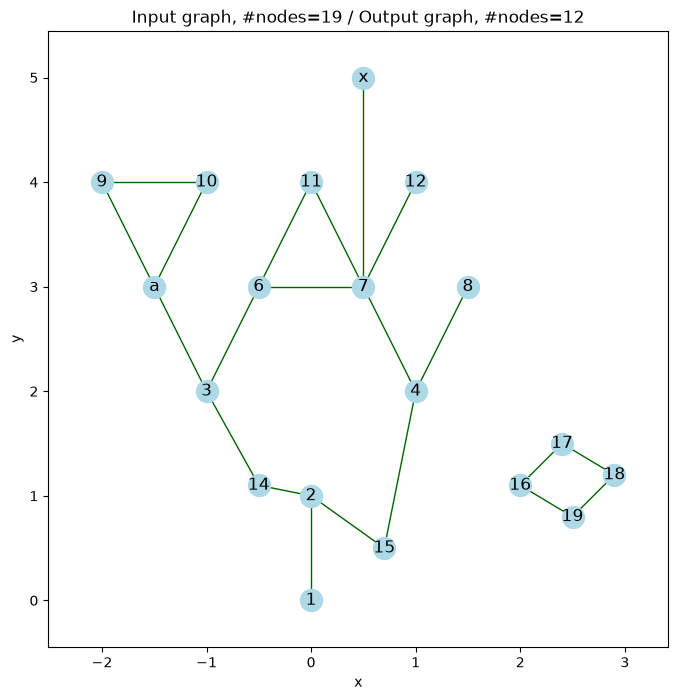

In [14]:
# Options for plot of 2D graph
options_out = {
    'node_size'   : 250,      # node size
    'node_color'  : 'orange', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,        # edge width
    'edge_color'  : 'red',    # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,     # show node labels ?
    #
    # axes
    'show_ticks'  : True,     # show ticks ?
    'axis_equal'  : True      # aspect ratio equal ?
}

# Plot
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
# kn.view.plot_graph2d(g, **options, alpha=0.3)
# kn.view.plot_graph2d(g_out, **options_out)
plt.title(f'Input graph, #nodes={g.number_of_nodes()} / Output graph, #nodes={g_out.number_of_nodes()}')
plt.show()

In [15]:
# Get information from `node_merging_count_dict`
nodes_removed = [n for n, c in node_merging_count_dict.items() if c == 0]
nodes_same    = [n for n, c in node_merging_count_dict.items() if c == 1]
nodes_new     = [n for n, c in node_merging_count_dict.items() if c > 1]
print('Removed nodes from input graph:', nodes_removed)
print('Same nodes as in input graph  :', nodes_same)
print('New nodes (aggregating several nodes in input graph):', nodes_new)
for n in nodes_new:
    print(f'- in ouput graph: new node {n} represents {node_merging_count_dict[n]} nodes from the input graph')

Removed nodes from input graph: [6, 7, 9, 10, 17, 18, 19]
Same nodes as in input graph  : [1, 2, 3, 4, 8, 12, 'x', 14, 15]
New nodes (aggregating several nodes in input graph): ['a', 11, 16]
- in ouput graph: new node a represents 3 nodes from the input graph
- in ouput graph: new node 11 represents 3 nodes from the input graph
- in ouput graph: new node 16 represents 4 nodes from the input graph


In [16]:
# Get information from `node_merging_list_dict`
print('In ouput graph:')
for u, u_list in node_merging_list_dict.items():
    if len(u_list) == 0:
        print(f'- node {u} has been removed')    
   
    elif len(u_list) == 1:
        print(f'- node {u} is unchanged (same as in input graph)')    

    else:
        print(f'- node {u} is a merging (aggregation) of the input graph nodes: {u_list}')


In ouput graph:
- node 1 is unchanged (same as in input graph)
- node 2 is unchanged (same as in input graph)
- node 3 is unchanged (same as in input graph)
- node 4 is unchanged (same as in input graph)
- node a is a merging (aggregation) of the input graph nodes: ['a', 9, 10]
- node 6 has been removed
- node 7 has been removed
- node 8 is unchanged (same as in input graph)
- node 9 has been removed
- node 10 has been removed
- node 11 is a merging (aggregation) of the input graph nodes: [11, 6, 7]
- node 12 is unchanged (same as in input graph)
- node x is unchanged (same as in input graph)
- node 14 is unchanged (same as in input graph)
- node 15 is unchanged (same as in input graph)
- node 16 is a merging (aggregation) of the input graph nodes: [16, 17, 18, 19]
- node 17 has been removed
- node 18 has been removed
- node 19 has been removed


In [17]:
np.all([node_merging_count_dict[u] == len(node_merging_list_dict[u]) for u in g.nodes]) # Should be True

np.True_

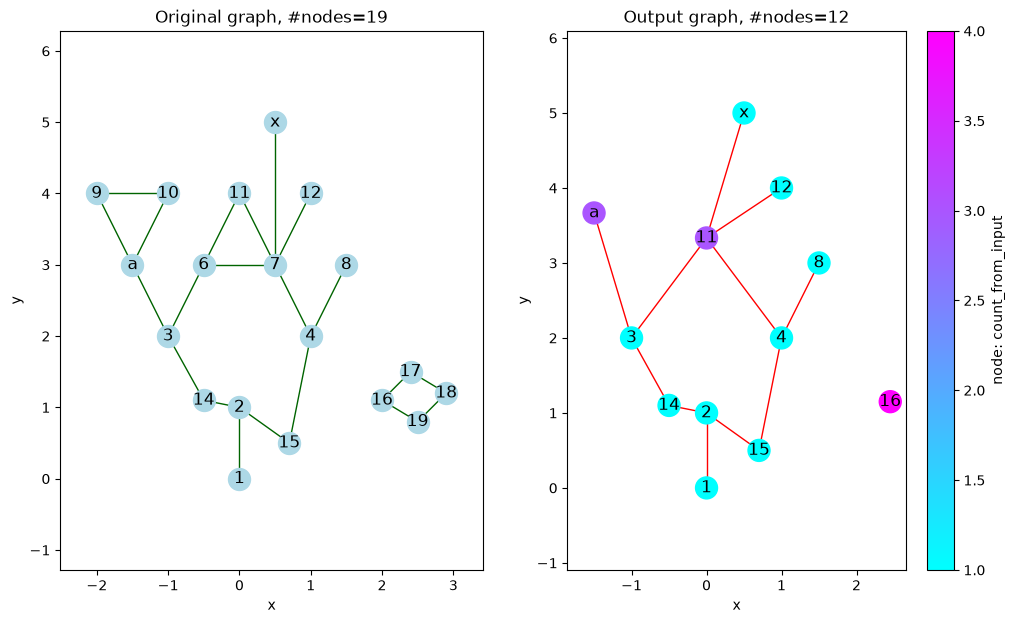

In [18]:
# Plot output graph nodes according to `node_merging_count_dict`
nx.set_node_attributes(g_out, node_merging_count_dict, 'count_from_input')

# Plot the graph

plt.subplots(1,2, figsize=(12, 7))
plt.subplot(1,2,1)
kn.view.plot_graph2d(g, **options)
# plt.grid()
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_out, node_attr='count_from_input', cmap='cool', **options_out)
plt.title(f'Output graph, #nodes={g_out.number_of_nodes()}')
# plt.grid()
plt.show()

## Example with another input graph

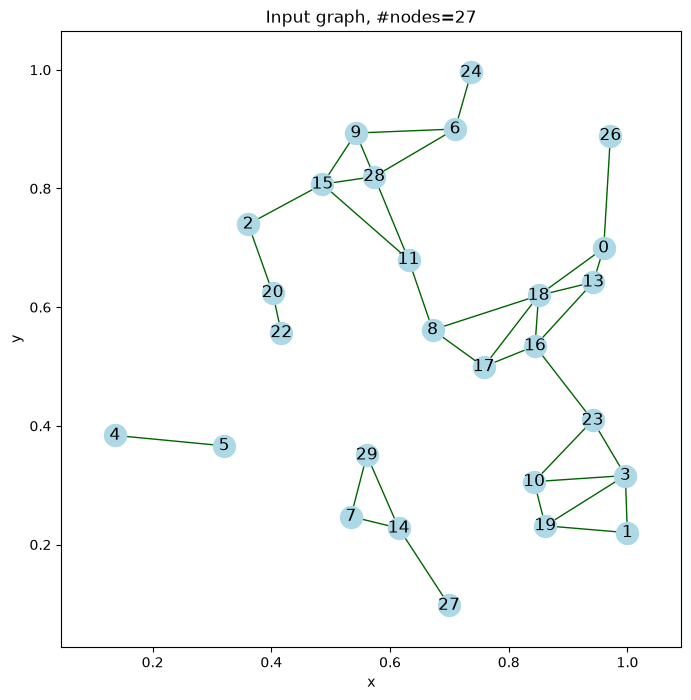

In [19]:
# Define an input graph (from Delaunay triangulation, and by removing edges and nodes)

# Number of points and seed
npoints = 30
seed = 24

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points, 
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points, min_edge_len=0.05, max_edge_len=0.20)

# Removed isolated nodes
g.remove_nodes_from([u for u in g.nodes() if len(g.edges(u))==0])

# Options for plot of 2D graph
options = {
    'node_size'   : 250,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'darkgreen', # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Plot the input graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'Input graph, #nodes={g.number_of_nodes()}')
plt.show()

In [20]:
g_out, node_merging_count_dict, node_merging_list_dict = kn.tools.remove_simple_cycles(
            g, 
            n_iter_max=None, 
            max_cycle_len=3, 
            node_attr_mode='mean', 
            return_node_merging_count_dict=True,
            return_node_merging_list_dict=True,
            verbose=1)

Iteration 1 : number of cycles to simplify = 4
Iteration 2 : number of cycles to simplify = 3
Iteration 3 : number of cycles to simplify = 0


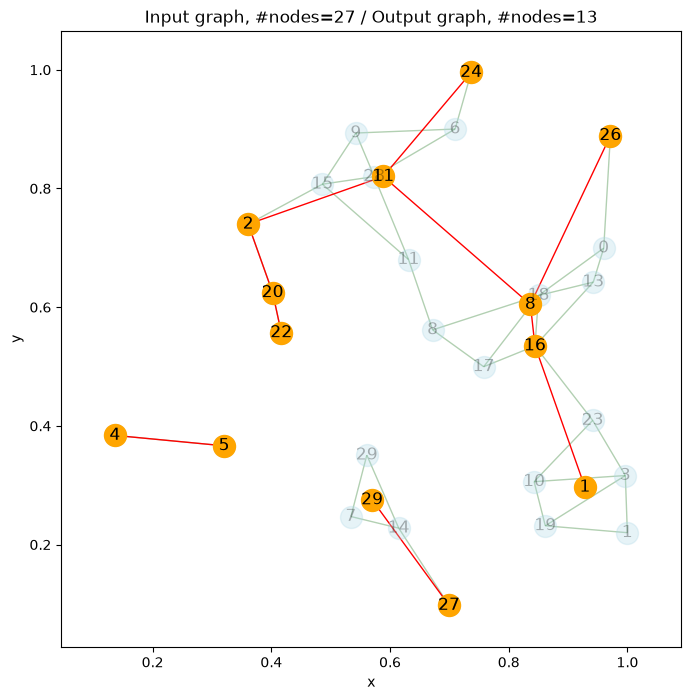

In [21]:
# Options for plot of 2D graph
options_out = {
    'node_size'   : 250,      # node size
    'node_color'  : 'orange', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,        # edge width
    'edge_color'  : 'red',    # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,     # show node labels ?
    #
    # axes
    'show_ticks'  : True,     # show ticks ?
    'axis_equal'  : True      # aspect ratio equal ?
}

# Plot
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options, alpha=0.3)
kn.view.plot_graph2d(g_out, **options_out)
plt.title(f'Input graph, #nodes={g.number_of_nodes()} / Output graph, #nodes={g_out.number_of_nodes()}')
plt.show()

In [22]:
# Get information from `node_merging_count_dict`
nodes_removed = [n for n, c in node_merging_count_dict.items() if c == 0]
nodes_same    = [n for n, c in node_merging_count_dict.items() if c == 1]
nodes_new     = [n for n, c in node_merging_count_dict.items() if c > 1]
print('Removed nodes from input graph:', nodes_removed)
print('Same nodes as in input graph  :', nodes_same)
print('New nodes (aggregating several nodes in input graph):', nodes_new)
for n in nodes_new:
    print(f'- in ouput graph: new node {n} represents {node_merging_count_dict[n]} nodes from the input graph')

Removed nodes from input graph: [9, 6, 28, 0, 3, 18, 10, 23, 15, 13, 7, 19, 14, 17]
Same nodes as in input graph  : [5, 4, 22, 24, 26, 20, 2, 27, 16]
New nodes (aggregating several nodes in input graph): [11, 8, 1, 29]
- in ouput graph: new node 11 represents 5 nodes from the input graph
- in ouput graph: new node 8 represents 5 nodes from the input graph
- in ouput graph: new node 1 represents 5 nodes from the input graph
- in ouput graph: new node 29 represents 3 nodes from the input graph


In [23]:
# Get information from `node_merging_list_dict`
print('In ouput graph:')
for u, u_list in node_merging_list_dict.items():
    if len(u_list) == 0:
        print(f'- node {u} has been removed')    
   
    elif len(u_list) == 1:
        print(f'- node {u} is unchanged (same as in input graph)')    

    else:
        print(f'- node {u} is a merging (aggregation) of the input graph nodes: {u_list}')


In ouput graph:
- node 5 is unchanged (same as in input graph)
- node 4 is unchanged (same as in input graph)
- node 22 is unchanged (same as in input graph)
- node 9 has been removed
- node 6 has been removed
- node 24 is unchanged (same as in input graph)
- node 28 has been removed
- node 26 is unchanged (same as in input graph)
- node 20 is unchanged (same as in input graph)
- node 2 is unchanged (same as in input graph)
- node 0 has been removed
- node 3 has been removed
- node 18 has been removed
- node 10 has been removed
- node 23 has been removed
- node 27 is unchanged (same as in input graph)
- node 15 has been removed
- node 11 is a merging (aggregation) of the input graph nodes: [11, 6, 9, 28, 15]
- node 8 is a merging (aggregation) of the input graph nodes: [8, 0, 18, 13, 17]
- node 13 has been removed
- node 16 is unchanged (same as in input graph)
- node 7 has been removed
- node 19 has been removed
- node 1 is a merging (aggregation) of the input graph nodes: [1, 3, 19, 

In [24]:
np.all([node_merging_count_dict[u] == len(node_merging_list_dict[u]) for u in g.nodes]) # Should be True

np.True_

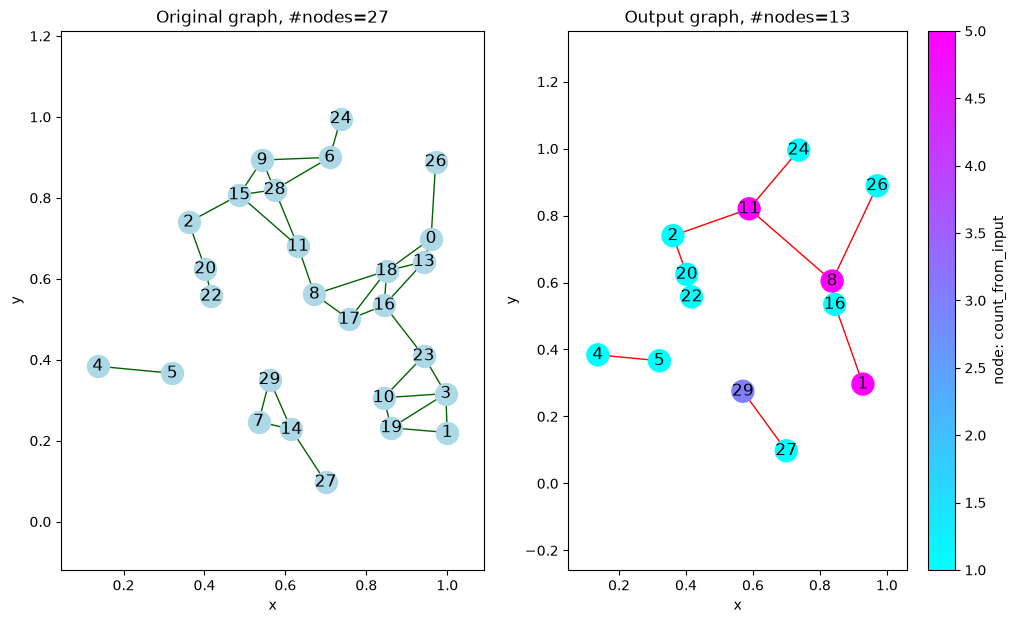

In [25]:
# Plot output graph nodes according to `node_merging_count_dict`
nx.set_node_attributes(g_out, node_merging_count_dict, 'count_from_input')

# Plot the graph

plt.subplots(1,2, figsize=(12, 7))
plt.subplot(1,2,1)
kn.view.plot_graph2d(g, **options)
# plt.grid()
plt.title(f'Original graph, #nodes={g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_out, node_attr='count_from_input', cmap='cool', **options_out)
plt.title(f'Output graph, #nodes={g_out.number_of_nodes()}')
# plt.grid()
plt.show()

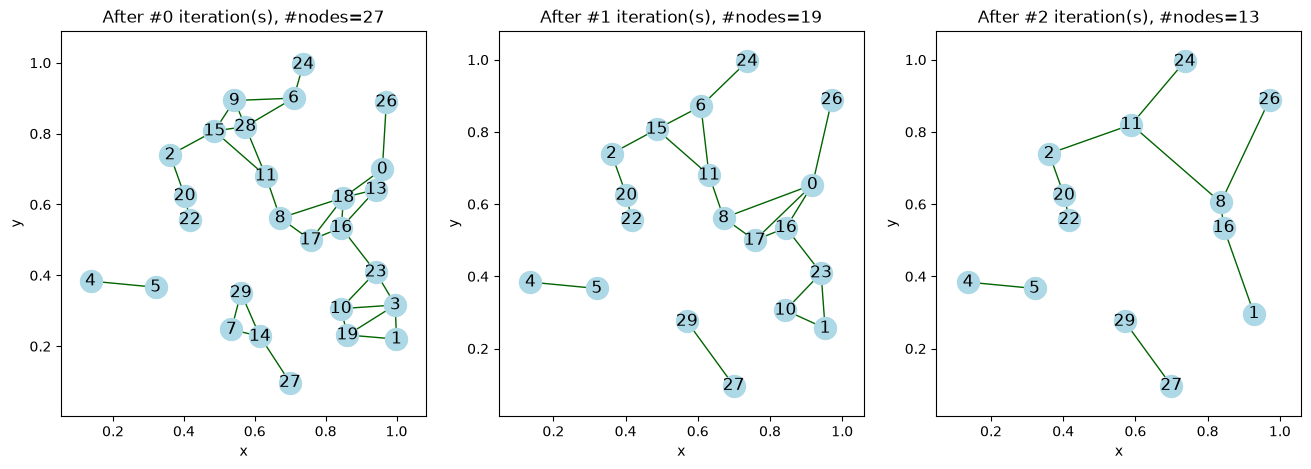

In [26]:
# Plot the graphs after each iteration

plt.subplots(1, 3, figsize=(16, 5))
for n in range(3):
    g_out = kn.tools.remove_simple_cycles(
        g, 
        n_iter_max=n, 
        max_cycle_len=3, 
        node_attr_mode='mean', 
        return_node_merging_count_dict=False,
        return_node_merging_list_dict=False,
        verbose=0)

    plt.subplot(1, 3, n+1)
    kn.view.plot_graph2d(g_out, **options)
    # plt.grid()
    plt.title(f'After #{n} iteration(s), #nodes={g_out.number_of_nodes()}')

plt.show()

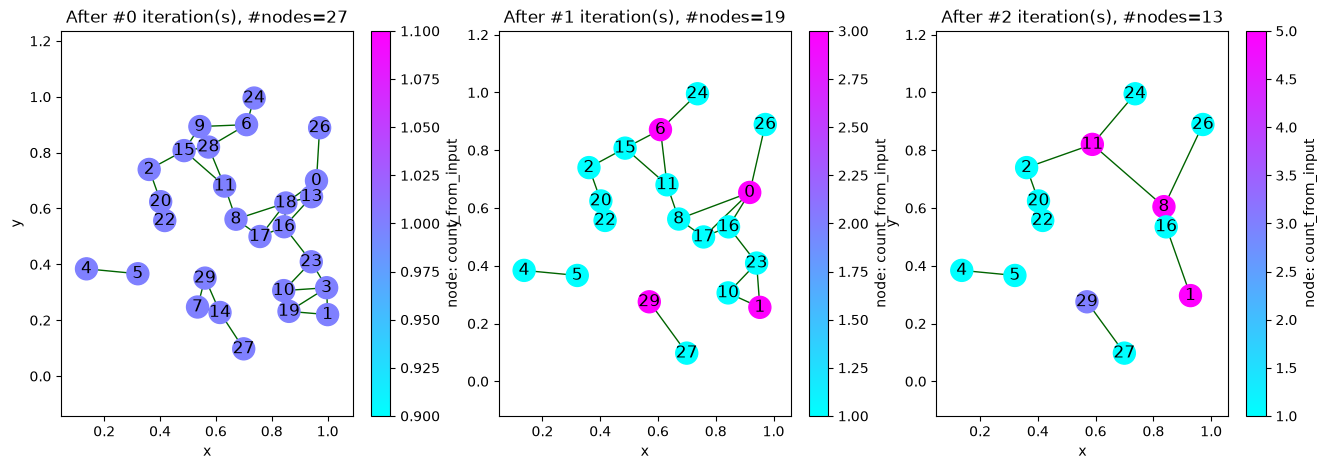

In [27]:
# Plot the graphs after each iteration with "count" for each node

plt.subplots(1, 3, figsize=(16, 5))
for n in range(3):
    g_out, node_merging_count_dict = kn.tools.remove_simple_cycles(
        g, 
        n_iter_max=n, 
        max_cycle_len=3, 
        node_attr_mode='mean', 
        return_node_merging_count_dict=True,
        return_node_merging_list_dict=False,
        verbose=0)
    nx.set_node_attributes(g_out, node_merging_count_dict, 'count_from_input')

    plt.subplot(1, 3, n+1)
    kn.view.plot_graph2d(g_out, node_attr='count_from_input', cmap='cool', **options)
    # plt.grid()
    plt.title(f'After #{n} iteration(s), #nodes={g_out.number_of_nodes()}')

plt.show()